In [14]:
from datascience import *
%matplotlib inline

import matplotlib.pyplot as plots
plots.style.use('fivethirtyeight')
import numpy as np

import warnings
warnings.simplefilter("ignore")

## Percentiles ##

Definition: Let p be a number between 0 and 100. The pth percentile of a collection is the smallest value in the collection that is at least as large as p% of all the values.

In [15]:
arr = make_array(1, 2, 3, 4, 5, 6, 7, 8, 9, 10)
arr

array([ 1,  2,  3,  4,  5,  6,  7,  8,  9, 10])

In [16]:
# returns 2 because
#   2 is at least as large as 20% of the items in arr
#   2 is the smallest value for which this is true
percentile(20, arr)

2

In [17]:
# returns 3 because
#   3 is at least as large as 30% of the items in arr
#   3 is the smallest value for which this is true
percentile(30, arr)

3

In [18]:
# returns 3 because
#   3 is at least as large as 25% of the items in arr
#   3 is the smallest value for which this is true
percentile(25, arr)

3

## Discussion Question


In [19]:
arr2 = make_array(1, 3, 5, 7, 9)

In [20]:
# What will the following commands return?

In [21]:
# This is called the first quartile
percentile(25, arr2)

3

In [22]:
# This is called the second quartile,
# more commonly known as the median
percentile(50, arr2)

5

In [23]:
# This is called the third quartile
percentile(75, arr2)

7

## Inference: Estimation

 Below is a table of approx. 45,000 randomly sampled San Francisco employees.

In [24]:
sf = Table.read_table('san_francisco_2019.csv')
sf.show(6)

Organization Group,Department,Job Family,Job,Salary,Overtime,Benefits,Total Compensation
Public Protection,Adult Probation,Information Systems,IS Trainer-Journey,91332,0,40059,131391
Public Protection,Adult Probation,Information Systems,IS Engineer-Assistant,123241,0,49279,172520
Public Protection,Adult Probation,Information Systems,IS Business Analyst-Senior,115715,0,46752,162468
Public Protection,Adult Probation,Information Systems,IS Business Analyst-Principal,159394,0,57312,216706
Public Protection,Adult Probation,Information Systems,IS Programmer Analyst,70035,0,28671,98706
Public Protection,Adult Probation,Information Systems,IS Project Director,175742,0,60830,236572


### Practice

Filter out people working less than part time (use a where command) and visualize the distribution with a histogram. Compute the mean and median of the resulting data set.

95857.4910924
89203.0


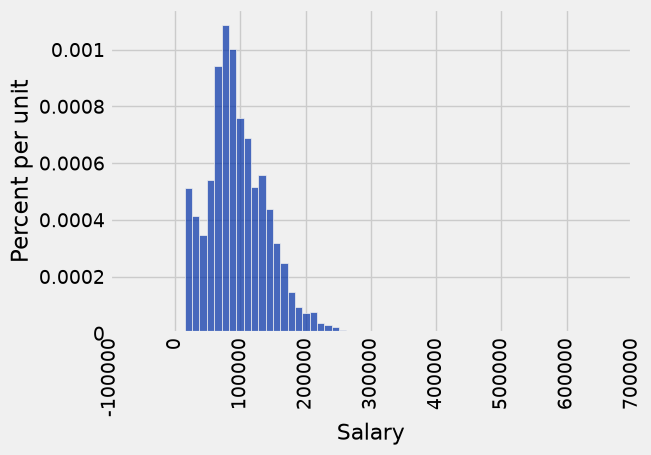

In [59]:
min_salary = 15 * 20 * 50 # $15/hr, 20 hr/wk, 50 weeks
full_time = sf.where('Salary', are.above(min_salary))
full_time.hist('Salary', bins=50)
pop_mean = np.average(full_time.column("Salary"))
pop_median = percentile(50, full_time.column('Salary'))
print(mean)
print(median)



That's the median of *our sample*. What is the median of the entire population?

# Bootstrap

In the bootstrap technique, we:
 - sample randomly
 - from the original sample
 - with replacement
 - the same number of times as the original sample size

Default behavior of `tbl.sample`: at random with replacement, the same number of times as rows of `tbl`

89314.0

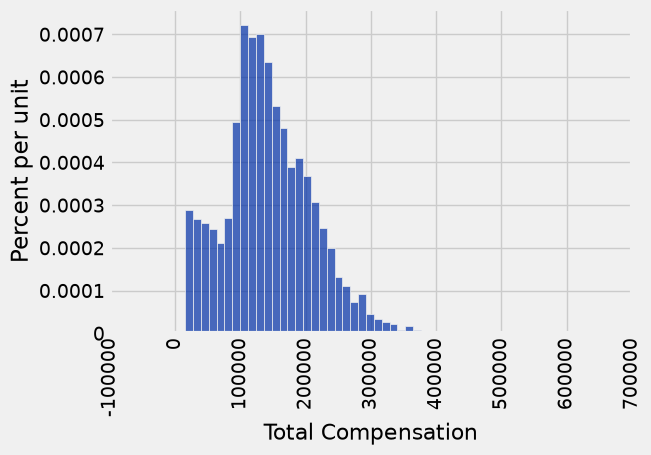

In [51]:
#bootstrap_sample = full_time.sample(full_time.num_rows, with_replacement = True)
bootstrap_sample = full_time.sample() # draw a new sample of the same size based on our data
bootstrap_sample.hist('Total Compensation', bins=50)
bootstrap_salary_col = bootstrap_sample.column("Salary")
percentile(50, bootstrap_salary_col)


### Practice

Write a function called one_bootstrap_median that resamples the table and returns the median.

In [65]:
def one_bootstrap_median():
    sampledtable = full_time.sample()
    bootstrap_salary_column = sampledtable.column('Salary')
    median_sample = percentile(50, bootstrap_salary_column)
    return median_sample

In [66]:
one_bootstrap_median()

89160.0

### Practice

Simulate 1000 bootstrapped medians and gather the results into an array.

In [67]:

bootstrap_medians = make_array()
for _ in np.arange(100):
    results = one_bootstrap_median()
    bootstrap_medians = np.append(bootstrap_medians, results)

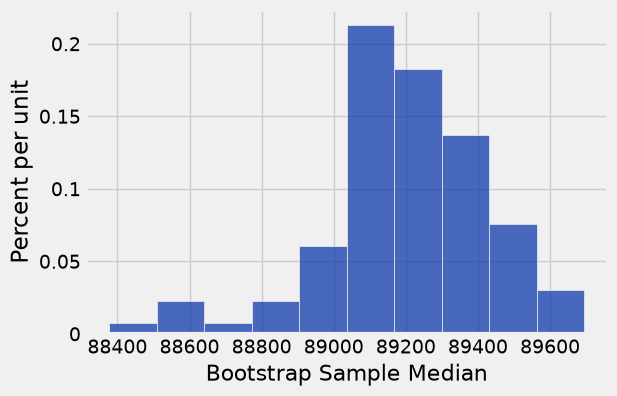

In [68]:
resampled_medians = Table().with_column('Bootstrap Sample Median', bootstrap_medians)
resampled_medians.hist(bins = 10)

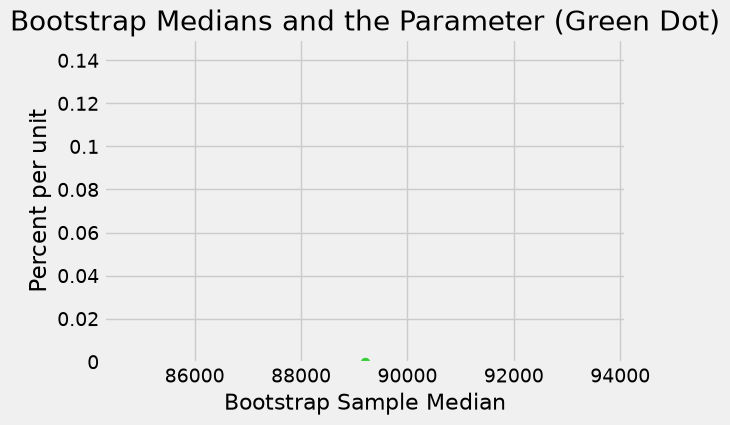

In [60]:
# Code to visualize the bootstrapped medians

resampled_medians = Table().with_column('Bootstrap Sample Median', bootstrap_medians)

median_bins=np.arange(134000, 138000, 200)
resampled_medians.hist(bins = median_bins)

# Plotting parameters; you can ignore this code
parameter_green = '#32CD32'
plots.ylim(-0.000005, 0.0015)
plots.scatter(pop_median, 0, color=parameter_green, s=40, zorder=2)
plots.title('Bootstrap Medians and the Parameter (Green Dot)');

## Percentile Method: Middle 95% of the Bootstrap Estimates 

### Practice

Find the middle 95% of the estimates by computing the 2.5 and 97.5 percentile.

In [ ]:
left = ... # 2.5 percentile
right = ... # 97.5 percentile

make_array(left, right)

In [ ]:
# Code to visualize confidence interval

resampled_medians.hist(bins = median_bins)

# Plotting parameters; you can ignore this code
plots.ylim(-0.0001, 0.0015)
plots.plot(make_array(left, right), make_array(0, 0), color='yellow', lw=3, zorder=1)
plots.scatter(pop_median, 0, color=parameter_green, s=40, zorder=2);

This is called a **confidence interval**. In 95% of simulations, the median fell between these two values.

"We are 95% confident that the median salary of the entire population is between these two values."
